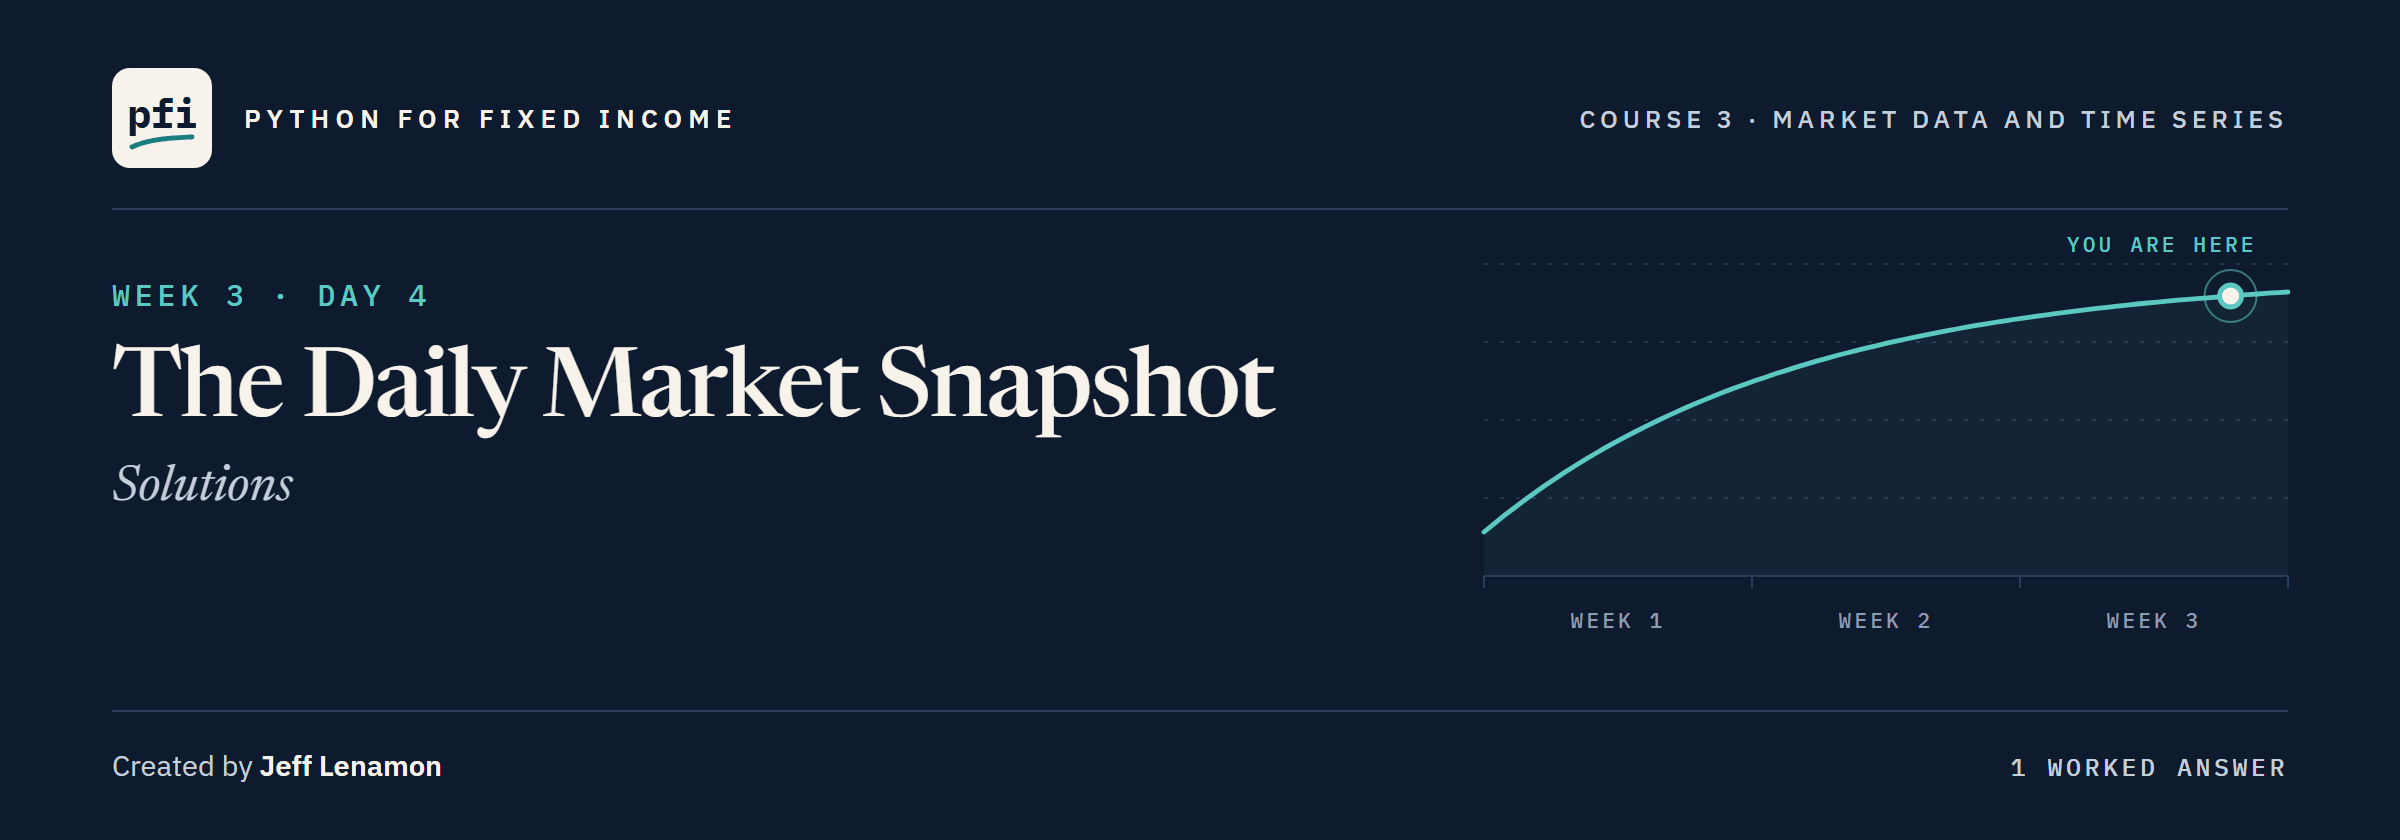

# The Daily Market Snapshot: Solutions

Week 3, Day 4. Worked answers to the exercises. Try each one yourself first.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course03_market_data/week3/day4/14_the_daily_market_snapshot_solutions.ipynb)

## Exercises

Run the next cells first: the work folder, with the module, tests and script as this notebook leaves them, the imports, the market and the book, and `check`.

In [1]:
import os
import sys

# start_day.py sets up each day. On your machine Python finds it in the repo's start_of_day folder;
# in Colab there is no repo, so the cell downloads it from the course's GitHub page.
github = 'https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/'
if os.path.exists('../../start_of_day/start_day.py'):
    sys.path.insert(0, '../../start_of_day')
else:
    !wget -q {github}course03_market_data/start_of_day/start_day.py
from start_day import start_day

# a new work folder: the data files, Course 2's bondmath.py, and marketdata.py and its tests
# as notebook 14 ends.
# To start the day again, restart the kernel and run all cells.
work = start_day(14, after=14)

Work folder pfi_course3_14_k4w7q2xr: 8 data files, Course 2's bondmath.py, marketdata.py as notebook 14 left it, 14 commits, tagged week1 and week2


In [2]:
import importlib

import pandas as pd

import marketdata as md

treasury = pd.read_csv('treasury_par_yields.csv', parse_dates=['date'], index_col='date',
                       float_precision='round_trip')
spreads = pd.read_csv('course3_synthetic_spreads.csv', parse_dates=['date'], index_col='date',
                      float_precision='round_trip')
market = treasury.join(spreads, validate='one_to_one')
book = pd.read_csv('holdings.csv')
SNAPSHOT_UNITS = {'2 Yr': 'pct', '5 Yr': 'pct', '10 Yr': 'pct', '30 Yr': 'pct',
                  'ig_spread_bp': 'bp', 'hy_spread_bp': 'bp'}
print(f'{len(market):,} rows to {market.index[-1]:%Y-%m-%d}; {len(book)} bonds')

2,940 rows to 2026-10-02; 200 bonds


In [3]:
# check() compares your answer with the expected one and prints the result
def check(label, answer, expected):
    if answer is ...:
        print(label + ': not attempted yet')
        return
    if answer is None:
        print(label + ': not yet. Nothing came back: does your function end with return?')
        return
    # isinstance(x, list) is True when x is a list, so a list answer is compared value by value
    if isinstance(expected, list):
        correct = list(answer) == expected  # the same values in the same order
    # getattr(answer, 'ndim', 0) reads answer's ndim, its number of dimensions, as in NumPy
    # Part 1, and gives 0 when answer has none: a single number or a piece of text
    elif getattr(answer, 'ndim', 0) > 0:
        correct = False  # a column or a table where one value is expected
    elif isinstance(expected, float):
        # abs() drops the sign, so this is the size of the gap between the two decimals
        correct = abs(answer - expected) < 0.000001  # decimals: within a tiny tolerance
    else:
        correct = answer == expected
    print(label + ': correct' if correct else label + ': not yet. You have ' + str(answer))

### Exercise 1

In [4]:
tables_15 = md.snapshot_tables(market, book, '2026-09-15', SNAPSHOT_UNITS)
ex1_level = tables_15['levels'].loc['10 Yr', 'level']
ex1_book_change = round(tables_15['book'].iloc[-1]['mv_change_usd'], 2)
print(f'10 Yr on 2026-09-15: {ex1_level} percent; book what-if: {ex1_book_change:,.2f} dollars')

10 Yr on 2026-09-15: 5.0 percent; book what-if: -872,595.85 dollars


In [5]:
check('Exercise 1 the 10 Yr level', ex1_level, 5.0)
check('Exercise 1 the book what-if', ex1_book_change, -872595.85)

Exercise 1 the 10 Yr level: correct
Exercise 1 the book what-if: correct


The same function, another date: the page for 15 September reads nothing after it.

### Exercise 2

In [6]:
tables_02 = md.snapshot_tables(market, book, '2026-10-02', SNAPSHOT_UNITS)
five_thirty = md.slope_bp(market, '5 Yr', '30 Yr')
row_63 = md.summary_table(pd.DataFrame({'5s30s': five_thirty}), '2026-10-02', {'5s30s': 'bp'},
                          window=63)
row_63 = row_63.rename(index={'5s30s': '5s30s (63 rows)'})
ex2_table = pd.concat([tables_02['slopes_flies'], row_63])
ex2_rows = len(ex2_table)
ex2_zscore = ex2_table.loc['5s30s (63 rows)', 'zscore']
ex2_table.round(2)

,unit,level,chg_1d_bp,chg_1w_bp,chg_1m_bp,zscore,pct_rank
series,,,,,,,
2s10s,bp,45.0,-1.0,9.0,5.0,-0.51,28.17
5s30s,bp,57.0,-3.0,6.0,-16.0,-2.07,5.95
3m10y,bp,109.0,2.0,16.0,22.0,2.07,100.00
2s5s10s,bp,1.0,1.0,3.0,11.0,2.70,98.81
5s10s30s,bp,-13.0,1.0,0.0,10.0,2.58,100.00
5s30s (63 rows),bp,57.0,-3.0,6.0,-16.0,-1.08,23.81


In [7]:
check('Exercise 2 the rows', ex2_rows, 6)
check('Exercise 2 the 63-row z-score', ex2_zscore, -1.0784129299830423)

Exercise 2 the rows: correct
Exercise 2 the 63-row z-score: correct


The level and the changes match on both 5s30s rows; only the window of the z-score and the rank differs.
The window is part of the number's definition, which is why the row names it.

### Exercise 3

In [8]:
%%writefile -a marketdata.py


def snapshot_file_name(as_of, ext: str) -> str:
    """The file name of a snapshot: snapshot_YYYY-MM-DD.ext.

    Units: none; a date and an extension in, text out. Convention: the as-of date written as YYYY-MM-DD, so
    the names sort in date order, and ext is "html" or "xlsx", written without a dot.
    Raises ValueError for any other extension.
    """
    if ext not in ("html", "xlsx"):
        raise ValueError(f"ext must be 'html' or 'xlsx', not {ext!r}")
    return f"snapshot_{pd.Timestamp(as_of):%Y-%m-%d}.{ext}"

Appending to marketdata.py


In [9]:
%%writefile -a test_marketdata.py


def test_snapshot_file_name_sorts_by_date():
    assert md.snapshot_file_name("2026-09-30", "xlsx") == "snapshot_2026-09-30.xlsx"
    assert md.snapshot_file_name(pd.Timestamp("2026-10-02"), "html") == "snapshot_2026-10-02.html"
    # written as YYYY-MM-DD, the names sort as text in date order
    names = [md.snapshot_file_name(d, "html") for d in ["2026-10-02", "2026-09-15", "2026-09-30"]]
    assert sorted(names) == [md.snapshot_file_name(d, "html") for d in ["2026-09-15", "2026-09-30", "2026-10-02"]]
    with pytest.raises(ValueError):
        md.snapshot_file_name("2026-10-02", ".pdf")

Appending to test_marketdata.py


In [10]:
import subprocess
import sys

# python -m pytest -q on the test file, with this notebook's own Python and no cache folder
command = [sys.executable, '-m', 'pytest', '-q', '-p', 'no:cacheprovider', 'test_marketdata.py']
# run it in the work folder and keep what it prints
result = subprocess.run(command, cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

........................................................                 [100%]
56 passed in 0.50s



In [11]:
# the file changed, so reload before calling the new function
importlib.reload(md)
ex3_name = md.snapshot_file_name('2026-09-30', 'xlsx')
check('Exercise 3 the file name', ex3_name, 'snapshot_2026-09-30.xlsx')

Exercise 3 the file name: correct


Year, month, day, each with leading zeros: the names sort as text in date order, so a folder of snapshots lists oldest first.

### Exercise 4: AI check

The bug: `market.iloc[-1]` is the file's last row, not the row for `as_of`, and the function never reads `as_of` at all.
Run on a file that ends on 2 October, the page for 30 September shows 2 October's 5.28.
The fix keeps only the rows on or before `as_of`, as `snapshot_tables` does.

In [12]:
# written for this course in the style of an AI assistant's answer, now fixed
def snapshot_levels(market, as_of, units):
    """The level and one-day change of each series as of `as_of`, from rows on or before it only.

    Units: units[column] is "pct" (a yield, in percent) or "bp" (a spread); level in that
    unit, chg_1d_bp in bp. Convention: the level is the value on as_of, which must be a market
    date (a row of market); the change is from the previous observation. A row after as_of must
    never change the answer.
    """
    as_of = pd.Timestamp(as_of)
    if as_of not in market.index:
        raise ValueError(f"{as_of.date()} is not a market date")
    # the fix: keep only rows on or before as_of, so the last of them is as_of itself
    known = market.loc[:as_of]
    today = known.iloc[-1]
    previous = known.iloc[-2]
    rows = {}
    for column, unit in units.items():
        scale = 100 if unit == "pct" else 1
        change_bp = (today[column] - previous[column]) * scale
        rows[column] = {"level": today[column], "chg_1d_bp": change_bp}
    return pd.DataFrame.from_dict(rows, orient="index")

In [13]:
# the test, written from the docstring
levels_30 = snapshot_levels(market, '2026-09-30', SNAPSHOT_UNITS)
assert levels_30.loc['10 Yr', 'level'] == 5.29, 'the 10 Yr on 2026-09-30 was 5.29 percent'
# a row after the as-of date must change nothing: the same call on the market cut there
cut_market = market.loc[:'2026-09-30']
pd.testing.assert_frame_equal(levels_30, snapshot_levels(cut_market, '2026-09-30', SNAPSHOT_UNITS))
print("The level is 2026-09-30's, and later rows change nothing")

The level is 2026-09-30's, and later rows change nothing


In [14]:
ex4_level = levels_30.loc['10 Yr', 'level']
ex4_change = levels_30.loc['10 Yr', 'chg_1d_bp']
check('Exercise 4 the 10 Yr level', ex4_level, 5.29)
check('Exercise 4 the one-day change', ex4_change, 3.000000000000025)

Exercise 4 the 10 Yr level: correct
Exercise 4 the one-day change: correct


[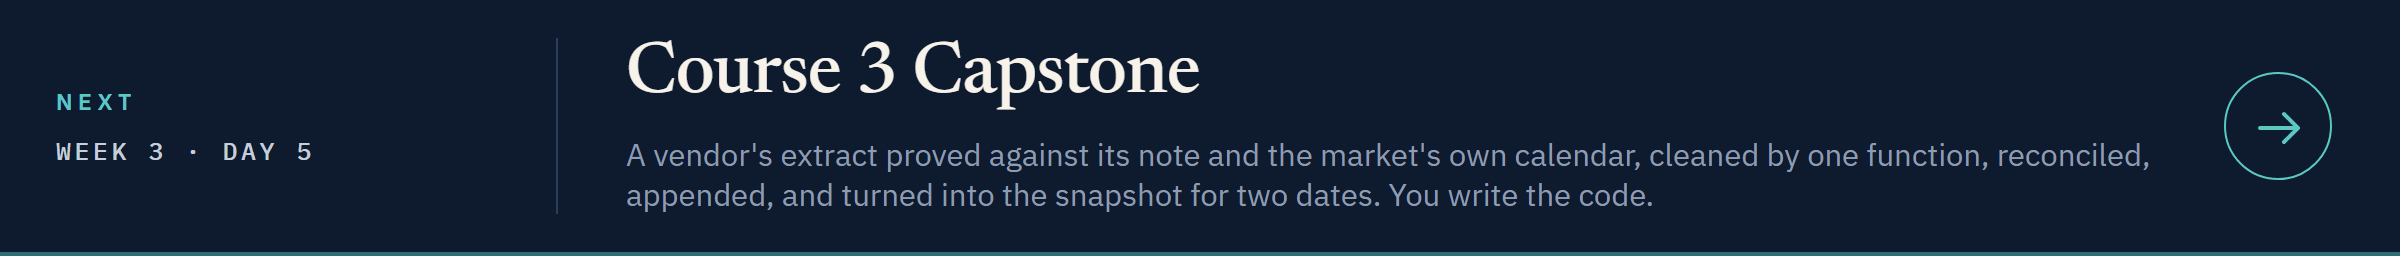](../day5/course3_capstone.ipynb)

[Open Day 5 in Colab](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course03_market_data/week3/day5/course3_capstone.ipynb)